# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Raisya Alayda
- **Email:** raisya7766@gmail.com
- **ID Dicoding:** rairay

## Menentukan Pertanyaan Bisnis

**Latar belakang.** Sebuah operator sepeda berbagi (*bike sharing*) di Washington D.C. ingin mengambil keputusan operasional dan pemasaran berbasis data. Dataset yang dipakai mencakup **1 Januari 2011 – 31 Desember 2012** (731 hari / 17.379 jam pencatatan). Berikut tiga pertanyaan bisnis yang disusun dengan kerangka **SMART**:

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada **hari kerja** dibandingkan **akhir pekan/hari libur** sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak tersebut, agar tim operasional dapat menjadwalkan redistribusi dan perawatan sepeda di luar jam puncak?
- **Pertanyaan 2:** Berapa persen perbedaan rata-rata penyewaan harian pada kondisi cuaca **berkabut/berawan** dan **hujan/salju ringan** dibandingkan cuaca **cerah**, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011–2012, agar tim pemasaran dapat menentukan waktu promosi dan kebijakan ukuran armada?
- **Pertanyaan 3:** Berapa persentase pertumbuhan total penyewaan tahun 2012 dibandingkan 2011 (secara keseluruhan, per bulan, serta per segmen pengguna *casual* vs *registered*), agar manajemen dapat menentukan segmen yang harus diprioritaskan pada strategi akuisisi dan retensi?

**Pemetaan SMART**

| Elemen | Penjelasan |
|---|---|
| **Specific** | Setiap pertanyaan fokus pada satu topik: pola jam (P1), cuaca & musim (P2), pertumbuhan tahunan & segmen pengguna (P3). |
| **Measurable** | Dijawab dengan angka: rata-rata penyewaan per jam, selisih jam puncak, persen perbedaan rata-rata harian, persen pertumbuhan. |
| **Action-Oriented** | Hasil langsung mengarah ke tindakan: jadwal redistribusi sepeda, waktu promosi/ukuran armada, prioritas segmen pengguna. |
| **Relevant** | Utilisasi armada, pendapatan, dan pertumbuhan pengguna adalah masalah inti bisnis bike sharing. |
| **Time-bound** | Seluruh analisis dibatasi pada periode 2011–2012. |

## Import Semua Packages/Library yang Digunakan

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Palet warna konsisten: biru tua = fokus utama, oranye = pembanding, abu-abu = pendukung
BLUE, ORANGE, GREY, RED = '#1f4e79', '#e08e0b', '#b8b8b8', '#c0392b'

## Data Wrangling

### Gathering Data

#### Load day_df dan hour_df

In [14]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print('Ukuran day_df  :', day_df.shape)
print('Ukuran hour_df :', hour_df.shape)
day_df.head()

Ukuran day_df  : (731, 16)
Ukuran hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [15]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 hari dan `hour_df` berisi 17.379 jam; keduanya memuat 2 tahun penuh (2011–2012).
- `hour_df` dipakai untuk analisis pola jam (Pertanyaan 1), sedangkan `day_df` dipakai untuk cuaca, musim, dan pertumbuhan (Pertanyaan 2 dan 3).

### Assessing Data

#### Memeriksa tipe data, missing value, dan data duplikat

In [16]:
for nama, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'===== {nama} =====')
    df.info()
    print('Missing value per kolom:')
    print(df.isna().sum().to_string())
    print('Jumlah baris duplikat   :', df.duplicated().sum())
    print()

===== day_df =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Missing value per kolom:
instant       0
dteday        0
season        0
y

**Temuan:** tidak ada *missing value* dan tidak ada baris duplikat pada kedua tabel. Masalah yang terlihat: kolom `dteday` bertipe teks (`str`/`object`), bukan *datetime* (**masalah tipe data**).

#### Ringkasan statistik dengan `describe()`

In [17]:
day_df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.00,211.17,1.00,183.50,366.00,548.50,731.00
season,731.0,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,731.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,731.0,6.52,3.45,1.00,4.00,7.00,10.00,12.00
holiday,731.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,731.0,3.00,2.00,0.00,1.00,3.00,5.00,6.00
workingday,731.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,731.0,1.40,0.54,1.00,1.00,1.00,2.00,3.00
temp,731.0,0.50,0.18,0.06,0.34,0.50,0.66,0.86
atemp,731.0,0.47,0.16,0.08,0.34,0.49,0.61,0.84


In [18]:
hour_df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.00,5017.03,1.00,4345.50,8690.00,13034.50,17379.00
season,17379.0,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,17379.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,17379.0,6.54,3.44,1.00,4.00,7.00,10.00,12.00
hr,17379.0,11.55,6.91,0.00,6.00,12.00,18.00,23.00
holiday,17379.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,17379.0,3.00,2.01,0.00,1.00,3.00,5.00,6.00
workingday,17379.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,17379.0,1.43,0.64,1.00,1.00,1.00,2.00,4.00
temp,17379.0,0.50,0.19,0.02,0.34,0.50,0.66,1.00


**Temuan:** nilai minimum `hum` adalah **0** pada kedua tabel (tidak wajar untuk kelembapan udara), dan nilai maksimum `casual` (3.410) jauh di atas rata-ratanya. Kedua hal ini diperiksa lebih lanjut di bawah. Selain itu, `weathersit` pada `hour_df` bernilai 1–4, sedangkan pada `day_df` hanya 1–3.

#### Memeriksa invalid value (kelembapan = 0)

In [19]:
print('day_df  -> baris dengan hum = 0 :', (day_df['hum'] == 0).sum())
print('hour_df -> baris dengan hum = 0 :', (hour_df['hum'] == 0).sum())
print('Tanggal pada day_df  :', day_df.loc[day_df['hum'] == 0, 'dteday'].tolist())
print('Tanggal pada hour_df :', hour_df.loc[hour_df['hum'] == 0, 'dteday'].unique().tolist())
print()
# Bandingkan dengan hari-hari di sekitarnya
day_df.loc[66:70, ['dteday', 'hum', 'temp', 'weathersit', 'cnt']]

day_df  -> baris dengan hum = 0 : 1
hour_df -> baris dengan hum = 0 : 22
Tanggal pada day_df  : ['2011-03-10']
Tanggal pada hour_df : ['2011-03-10']



,dteday,hum,temp,weathersit,cnt
66,2011-03-08,0.420833,0.292500,1,2133
67,2011-03-09,0.775417,0.295833,2,1891
68,2011-03-10,0.000000,0.389091,3,623
69,2011-03-11,0.649565,0.316522,2,1977
70,2011-03-12,0.594583,0.329167,1,2132


**Temuan:** seluruh baris `hum = 0` berasal dari satu hari, **2011-03-10** (1 baris di `day_df`, 22 jam di `hour_df`). Kelembapan hari-hari di sekitarnya adalah 0,42 (8 Maret), 0,78 (9 Maret), 0,65 (11 Maret), dan 0,59 (12 Maret), sehingga nilai 0 pada 10 Maret tidak wajar dan dianggap **invalid value** (kemungkinan sensor gagal mencatat).

#### Memeriksa inaccurate value (label musim)

In [20]:
# Rentang tanggal tiap kode musim
print(day_df.groupby('season')['dteday'].agg(['min', 'max']))
print()
# Tanggal ketika kode musim berganti
day_df.loc[day_df['season'].diff() != 0, ['dteday', 'season']].head(6)

               min         max
season                        
1       2011-01-01  2012-12-31
2       2011-03-21  2012-06-20
3       2011-06-21  2012-09-22
4       2011-09-23  2012-12-20



,dteday,season
0,2011-01-01,1
79,2011-03-21,2
171,2011-06-21,3
265,2011-09-23,4
354,2011-12-21,1
445,2012-03-21,2


**Temuan:** Readme mendefinisikan `season` 1 = spring, 2 = summer, 3 = fall, 4 = winter. Namun kode musim berganti pada 21 Maret, 21 Juni, 23 September, dan 21 Desember, yaitu titik balik musim astronomis, dan kode 1 berisi 1 Januari 2011. Berdasarkan tanggal, yang konsisten adalah **1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall**.

#### Memeriksa outlier

In [21]:
def batas_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

ringkasan = []
for kolom in ['windspeed', 'casual', 'registered', 'cnt']:
    bb, ba = batas_iqr(day_df[kolom])
    n = ((day_df[kolom] < bb) | (day_df[kolom] > ba)).sum()
    ringkasan.append({'kolom': kolom, 'jumlah_outlier': n, 'persen': round(n / len(day_df) * 100, 2),
                      'batas_bawah': round(bb, 3), 'batas_atas': round(ba, 3)})
pd.DataFrame(ringkasan)

,kolom,jumlah_outlier,persen,batas_bawah,batas_atas
0,windspeed,13,1.78,-0.012,0.381
1,casual,44,6.02,-855.250,2266.750
2,registered,0,0.00,-922.250,8195.750
3,cnt,0,0.00,-1054.000,10162.000


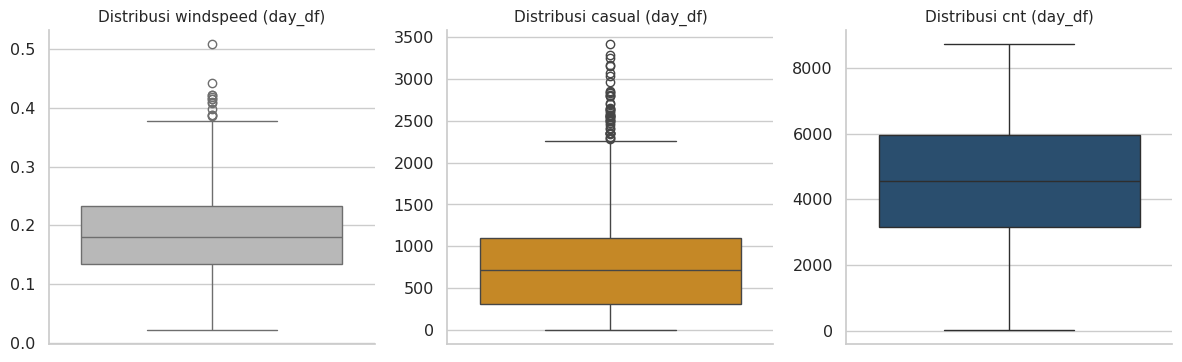

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, kolom, warna in zip(axes, ['windspeed', 'casual', 'cnt'], [GREY, ORANGE, BLUE]):
    sns.boxplot(y=day_df[kolom], ax=ax, color=warna)
    ax.set_title(f'Distribusi {kolom} (day_df)', fontsize=11)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

Karena outlier casual terbanyak, karakteristik hari-hari outlier tersebut diperiksa untuk menilai apakah itu kesalahan data atau variasi nyata.

In [24]:
_, batas_atas_casual = batas_iqr(day_df['casual'])
outlier_casual = day_df[day_df['casual'] > batas_atas_casual]

print('Jumlah hari outlier casual :', len(outlier_casual))
print()
print('Tipe hari (workingday):')
print(outlier_casual['workingday'].map({0: 'Akhir pekan/libur', 1: 'Hari kerja'}).value_counts().to_string())
print()
print('Kondisi cuaca (weathersit):')
print(outlier_casual['weathersit'].map({1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan'}).value_counts().to_string())
print()

min_temp = round((outlier_casual['temp'] * 41).min(), 2)
max_temp = round((outlier_casual['temp'] * 41).max(), 2)
print('Suhu (derajat C): min =', min_temp, '| maks =', max_temp)

Jumlah hari outlier casual : 44

Tipe hari (workingday):
workingday
Akhir pekan/libur    43
Hari kerja            1

Kondisi cuaca (weathersit):
weathersit
Cerah               32
Berkabut/Berawan    12

Suhu (derajat C): min = 17.25 | maks = 32.53


**Temuan:** terdapat 13 hari outlier `windspeed` dan 44 hari outlier `casual`. Dari 44 hari outlier `casual`, 43 hari terdapat pada akhir pekan/libur (`workingday = 0`), 32 hari bercuaca cerah dan 12 berkabut/berawan, dengan suhu 17,25–32,53°C. Pola ini konsisten dengan hari rekreasi yang ramai, bukan kesalahan pencatatan.

#### Memeriksa kelengkapan data per jam dan konsistensi total

In [25]:
jam_seharusnya = day_df.shape[0] * 24
print('Jumlah jam seharusnya :', jam_seharusnya)
print('Jumlah jam tercatat   :', hour_df.shape[0])
print('Jam tidak tercatat    :', jam_seharusnya - hour_df.shape[0])
print('Baris casual + registered != cnt :',
      (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum(), '(day) /',
      (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum(), '(hour)')

Jumlah jam seharusnya : 17544
Jumlah jam tercatat   : 17379
Jam tidak tercatat    : 165
Baris casual + registered != cnt : 0 (day) / 0 (hour)


Selanjutnya dicari jam, tipe hari, tahun, dan tanggal mana yang tidak tercatat, dengan membandingkan data dengan kalender lengkap.

In [27]:
tanggal = pd.to_datetime(day_df['dteday'])
kalender = pd.MultiIndex.from_product([tanggal, range(24)], names=['dteday', 'hr']).to_frame(index=False)
tercatat = hour_df.assign(dteday=pd.to_datetime(hour_df['dteday']))[['dteday', 'hr']]
hilang = (kalender.merge(tercatat, how='left', indicator=True)
          .query('_merge == "left_only"').drop(columns='_merge'))
info_hari = day_df.assign(dteday=tanggal)[['dteday', 'workingday', 'yr']]
hilang = hilang.merge(info_hari, on='dteday')
hilang['tipe_hari'] = hilang['workingday'].map({0: 'Akhir Pekan/Libur', 1: 'Hari Kerja'})

print('Jam hilang :', len(hilang), '| tersebar pada', hilang['dteday'].nunique(), 'hari dari', len(day_df), 'hari')

# Per kelompok jam
kel_jam = pd.cut(hilang['hr'], bins=[-1, 5, 9, 15, 19, 23],
                 labels=['00-05', '06-09', '10-15', '16-19', '20-23'])
print()
print('Jam hilang per kelompok jam:')
print(kel_jam.value_counts().sort_index().to_string())

# Per tipe hari dibanding proporsi harinya
perbandingan = pd.DataFrame({
    'jam_hilang': hilang['tipe_hari'].value_counts(),
    'porsi_jam_hilang_%': (hilang['tipe_hari'].value_counts(normalize=True) * 100).round(1),
    'porsi_hari_di_data_%': (day_df['workingday'].map({0: 'Akhir Pekan/Libur', 1: 'Hari Kerja'})
                             .value_counts(normalize=True) * 100).round(1)})
print()
print('Per tipe hari:')
print(perbandingan.to_string())
print()
print('Per tahun:')
print(hilang['yr'].map({0: 2011, 1: 2012}).value_counts().to_string())
print()
print('Lima tanggal dengan jam hilang terbanyak:')
print(hilang.groupby('dteday').size().nlargest(5).to_string())

Jam hilang : 165 | tersebar pada 76 hari dari 731 hari

Jam hilang per kelompok jam:
hr
00-05    110
06-09     18
10-15     17
16-19      8
20-23     12

Per tipe hari:
                   jam_hilang  porsi_jam_hilang_%  porsi_hari_di_data_%
Hari Kerja                135                81.8                  68.4
Akhir Pekan/Libur          30                18.2                  31.6

Per tahun:
yr
2011    115
2012     50

Lima tanggal dengan jam hilang terbanyak:
dteday
2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8


**Temuan:** 165 jam hilang tersebar pada 76 hari. Dua pertiga (110 jam) berada pada pukul 00.00–05.00. Hari kerja memiliki 81,8% jam hilang, lebih tinggi dari porsinya di data (68,4%). Kehilangan juga terpusat pada tanggal tertentu, misalnya 2012-10-29 (23 jam), 2011-01-27 (16 jam), dan 2012-10-30 (13 jam). Dengan demikian jam yang hilang **tidak acak**, sehingga dampaknya terhadap rata-rata per jam perlu diuji (lihat tahap Cleaning).

**Steps to Take** (setiap masalah dipasangkan dengan tindakan pada tahap Cleaning):
- **Invalid type (`dteday`):** ubah menjadi tipe *datetime* di kedua tabel.
- **Invalid value (`hum = 0` pada 2011-03-10):** ubah nilai 0 menjadi `NaN`, lalu isi dengan interpolasi linear dari nilai sebelum dan sesudahnya.
- **Inaccurate value (label musim) dan kode numerik lain:** beri label musim berdasarkan tanggal (1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall), serta ubah `yr`, `mnth`, `weekday`, `weathersit`, `workingday` menjadi label yang mudah dibaca. Kembalikan `temp`, `atemp`, `hum`, `windspeed` ke satuan asli (faktor 41, 50, 100, 67 menurut Readme).
- **Outlier (`casual`, `windspeed`):** tidak dihapus karena bukan kesalahan pencatatan; uji sensitivitas rata-rata dan median dengan dan tanpa hari outlier.
- **Jam tidak tercatat (165 jam):** tidak diisi (agar tidak mengarang data); uji sensitivitas pola per jam dengan membandingkan hasil pada semua hari vs hanya hari yang lengkap 24 jam.

**Insight:**
- Kualitas data umumnya baik (tanpa missing value dan duplikat), tetapi ada 5 isu: tipe `dteday`, kelembapan 0, label musim, outlier, dan 165 jam tidak tercatat.
- Label musim pada Readme tidak cocok dengan tanggal data, sehingga bila dipakai mentah akan menggeser hasil analisis musim.

### Cleaning Data

#### Fixing invalid type (`dteday`)

In [28]:
day_clean = day_df.copy()
hour_clean = hour_df.copy()

for df in (day_clean, hour_clean):
    df['dteday'] = pd.to_datetime(df['dteday'])

print('Tipe dteday day_clean  :', day_clean['dteday'].dtype)
print('Tipe dteday hour_clean :', hour_clean['dteday'].dtype)

Tipe dteday day_clean  : datetime64[ns]
Tipe dteday hour_clean : datetime64[ns]


#### Fixing invalid value (`hum = 0`)

In [31]:
for df in (day_clean, hour_clean):
    df['hum'] = df['hum'].replace(0, np.nan)

print('Jumlah NaN setelah hum = 0 diubah  :', day_clean['hum'].isna().sum(), '(day) /', hour_clean['hum'].isna().sum(), '(hour)')

for df in (day_clean, hour_clean):
    df['hum'] = df['hum'].interpolate(method='linear')   # data sudah berurutan menurut waktu

print('Jumlah NaN setelah interpolasi     :', day_clean['hum'].isna().sum(), '(day) /', hour_clean['hum'].isna().sum(), '(hour)')
print('Nilai hum 2011-03-10 (day)         :', day_clean.loc[day_clean['dteday'] == '2011-03-10', 'hum'].round(3).tolist())
print('Nilai minimum hum                  :', round(day_clean['hum'].min(), 3), '(day) /', round(hour_clean['hum'].min(), 3), '(hour)')

Jumlah NaN setelah hum = 0 diubah  : 0 (day) / 0 (hour)
Jumlah NaN setelah interpolasi     : 0 (day) / 0 (hour)
Nilai hum 2011-03-10 (day)         : [0.712]
Nilai minimum hum                  : 0.188 (day) / 0.08 (hour)


#### Fixing inaccurate label (musim), kode numerik, dan skala data

In [32]:
musim_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}   # berdasarkan titik balik musim pada data
cuaca_map = {1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan', 4: 'Hujan/Salju Lebat'}
hari_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
bulan_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
             7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}

def beri_label(df):
    df = df.copy()
    df['temp_c'] = (df['temp'] * 41).round(2)       # skala asli sesuai Readme
    df['atemp_c'] = (df['atemp'] * 50).round(2)
    df['humidity'] = (df['hum'] * 100).round(1)
    df['wind_kmh'] = (df['windspeed'] * 67).round(2)
    df['season_name'] = df['season'].map(musim_map)
    df['year'] = df['yr'].map({0: 2011, 1: 2012})
    df['month'] = df['mnth']
    df['month_name'] = df['mnth'].map(bulan_map)
    df['day_name'] = df['weekday'].map(hari_map)
    df['day_type'] = np.where(df['workingday'] == 1, 'Hari Kerja', 'Akhir Pekan/Libur')
    df['weather'] = df['weathersit'].map(cuaca_map)
    df = df.rename(columns={'cnt': 'total'})
    kolom = ['dteday', 'season_name', 'year', 'month', 'month_name', 'day_name', 'day_type',
             'holiday', 'workingday', 'weathersit', 'weather', 'temp_c', 'atemp_c', 'humidity',
             'wind_kmh', 'casual', 'registered', 'total']
    if 'hr' in df.columns:
        kolom.insert(3, 'hr')
    return df[kolom]

day_clean = beri_label(day_clean)
hour_clean = beri_label(hour_clean)

# Verifikasi: label musim harus sesuai bulan (Winter = Des-Mar, Summer = Jun-Sep, dst.)
print(pd.crosstab(day_clean['month_name'], day_clean['season_name']).reindex(list(bulan_map.values())))

season_name  Fall  Spring  Summer  Winter
month_name                               
Jan             0       0       0      62
Feb             0       0       0      57
Mar             0      22       0      40
Apr             0      60       0       0
Mei             0      62       0       0
Jun             0      40      20       0
Jul             0       0      62       0
Agu             0       0      62       0
Sep            16       0      44       0
Okt            62       0       0       0
Nov            60       0       0       0
Des            40       0       0      22


#### Handling outlier (`casual`)

Outlier dipertahankan. Untuk memastikan keputusan ini tidak mengubah kesimpulan, dihitung rata-rata dan median penyewaan harian dengan dan tanpa 44 hari outlier `casual`.

In [33]:
q1_c, q3_c = day_clean['casual'].quantile([0.25, 0.75])
batas_casual = q3_c + 1.5 * (q3_c - q1_c)
idx_outlier = day_clean.index[day_clean['casual'] > batas_casual]

uji_outlier = pd.DataFrame({
    'rata_rata_total_harian': [day_clean['total'].mean(), day_clean.drop(idx_outlier)['total'].mean()],
    'median_total_harian': [day_clean['total'].median(), day_clean.drop(idx_outlier)['total'].median()],
}, index=['Semua hari (731)', f'Tanpa hari outlier ({731 - len(idx_outlier)})']).round(0)
uji_outlier['selisih_rata_rata_%'] = ((uji_outlier['rata_rata_total_harian'] / uji_outlier.iloc[0, 0] - 1) * 100).round(1)
uji_outlier

,rata_rata_total_harian,median_total_harian,selisih_rata_rata_%
Semua hari (731),4504.0,4548.0,0.0
Tanpa hari outlier (687),4341.0,4381.0,-3.6


Rata-rata dan median bergeser sekitar 4%, sedangkan hari outlier adalah hari rekreasi yang valid. Data dipertahankan, dan median ditampilkan berdampingan dengan rata-rata pada EDA.

#### Handling jam tidak tercatat (sensitivity check)

Jam yang hilang tidak diisi karena akan mengarang data. Sebagai gantinya, pola per jam (dasar Pertanyaan 1) dihitung ulang hanya dari hari yang lengkap 24 jam, lalu dibandingkan dengan hasil pada semua hari.

In [34]:
jam_per_hari = hour_clean.groupby('dteday')['hr'].count()
hari_lengkap = jam_per_hari[jam_per_hari == 24].index
print('Hari lengkap 24 jam :', len(hari_lengkap), 'dari', len(jam_per_hari), 'hari')

baris = []
for tipe in ['Hari Kerja', 'Akhir Pekan/Libur']:
    semua = hour_clean[hour_clean['day_type'] == tipe].groupby('hr')['total'].mean()
    lengkap = (hour_clean[(hour_clean['day_type'] == tipe) & hour_clean['dteday'].isin(hari_lengkap)]
               .groupby('hr')['total'].mean())
    baris.append({'tipe_hari': tipe,
                  'jam_puncak_semua_hari': semua.idxmax(), 'nilai_puncak_semua_hari': round(semua.max(), 1),
                  'jam_puncak_hari_lengkap': lengkap.idxmax(), 'nilai_puncak_hari_lengkap': round(lengkap.max(), 1),
                  'selisih_nilai_puncak_%': round((lengkap.max() / semua.max() - 1) * 100, 1)})
pd.DataFrame(baris)

Hari lengkap 24 jam : 655 dari 731 hari


,tipe_hari,jam_puncak_semua_hari,nilai_puncak_semua_hari,jam_puncak_hari_lengkap,nilai_puncak_hari_lengkap,selisih_nilai_puncak_%
0,Hari Kerja,17,525.3,17,559.7,6.5
1,Akhir Pekan/Libur,13,372.7,13,390.8,4.9


**Hasil uji:** jam puncak **tidak berubah** (17.00 untuk hari kerja, 13.00 untuk akhir pekan/libur). Nilai puncaknya lebih tinggi sekitar 6,5% (hari kerja) dan 4,9% (akhir pekan) bila hanya hari lengkap yang dipakai, sehingga rata-rata per jam yang dilaporkan pada seluruh data sedikit lebih rendah (konservatif). Keterbatasan ini dicatat pada kesimpulan.

#### Verifikasi akhir hasil cleaning dan penyimpanan data bersih

In [35]:
print('Missing value day_clean  :', day_clean.isna().sum().sum())
print('Missing value hour_clean :', hour_clean.isna().sum().sum())
print()
print('===== day_clean =====')
day_clean.info()
print()
print('===== hour_clean =====')
hour_clean.info()

Missing value day_clean  : 0
Missing value hour_clean : 0

===== day_clean =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   dteday       731 non-null    datetime64[ns]
 1   season_name  731 non-null    object        
 2   year         731 non-null    int64         
 3   month        731 non-null    int64         
 4   month_name   731 non-null    object        
 5   day_name     731 non-null    object        
 6   day_type     731 non-null    object        
 7   holiday      731 non-null    int64         
 8   workingday   731 non-null    int64         
 9   weathersit   731 non-null    int64         
 10  weather      731 non-null    object        
 11  temp_c       731 non-null    float64       
 12  atemp_c      731 non-null    float64       
 13  humidity     731 non-null    float64       
 14  wind_kmh     731 non-null

In [36]:
day_clean.to_csv('dashboard/main_data.csv', index=False)
hour_clean.to_csv('dashboard/hour_data.csv', index=False)
print('Data bersih tersimpan di folder dashboard/')

Data bersih tersimpan di folder dashboard/


**Insight:**
- Tipe `dteday` sudah *datetime*, kelembapan tidak lagi bernilai 0, dan tidak ada missing value pada data bersih.
- Tabel silang bulan × musim memastikan label baru sesuai tanggal: Januari–Februari = Winter, Juli–Agustus = Summer, dan bulan Maret, Juni, September, Desember terbagi dua karena pergantian musim terjadi pada tanggal 20–23.
- Outlier dan jam hilang tidak mengubah kesimpulan utama (jam puncak sama), tetapi nilainya dilaporkan dengan catatan.
- Data bersih disimpan sebagai `main_data.csv` (harian) dan `hour_data.csv` (per jam) untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore statistik umum

Ringkasan statistik harian dan korelasi sederhana antara faktor lingkungan dan total penyewaan.

In [37]:
day_clean[['temp_c', 'humidity', 'wind_kmh', 'casual', 'registered', 'total']].describe().round(1)

,temp_c,humidity,wind_kmh,casual,registered,total
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.9,12.8,848.2,3656.2,4504.3
std,7.5,14.1,5.2,686.6,1560.3,1937.2
min,2.4,18.8,1.5,2.0,20.0,22.0
25%,13.8,52.1,9.0,315.5,2497.0,3152.0
50%,20.4,62.7,12.1,713.0,3662.0,4548.0
75%,26.9,73.0,15.6,1096.0,4776.5,5956.0
max,35.3,97.2,34.0,3410.0,6946.0,8714.0


In [38]:
print('Rata-rata penyewaan harian 2011 :', round(day_clean.query('year == 2011')['total'].mean()))
print('Rata-rata penyewaan harian 2012 :', round(day_clean.query('year == 2012')['total'].mean()))
print('Persentase registered terhadap total :', round(day_clean['registered'].sum() / day_clean['total'].sum() * 100, 1), '%')

# Korelasi faktor lingkungan terhadap total penyewaan harian
day_clean[['temp_c', 'humidity', 'wind_kmh', 'total']].corr()['total'].drop('total').round(2)

Rata-rata penyewaan harian 2011 : 3406
Rata-rata penyewaan harian 2012 : 5600
Persentase registered terhadap total : 81.2 %


,total
temp_c,0.63
humidity,-0.12
wind_kmh,-0.23


**Insight:**
- Rata-rata jumlah penyewaan sepeda per hari mencapai sekitar 4.504 kali, dengan jumlah terendah sebanyak 22 dan tertinggi 8.714 penyewaan. Hal ini menunjukkan adanya perbedaan tingkat permintaan yang cukup besar antarhari sehingga perlu dianalisis lebih lanjut berdasarkan waktu, kondisi cuaca, musim, dan tahun.
- Suhu memiliki hubungan positif yang cukup kuat dengan jumlah penyewaan sepeda (r ≈ 0,63). Sementara itu, kelembapan (r ≈ −0,12) dan kecepatan angin (r ≈ −0,23) menunjukkan hubungan negatif yang relatif lemah. Namun, hubungan tersebut tidak dapat langsung diartikan sebagai hubungan sebab-akibat.
- Pelanggan dengan kategori registered menjadi pengguna paling dominan, yaitu sekitar 81% dari keseluruhan jumlah penyewaan sepeda.

### Explore Pertanyaan 1
*Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak tersebut, agar tim operasional dapat menjadwalkan redistribusi dan perawatan sepeda di luar jam puncak?*

In [39]:
pola_jam = hour_clean.groupby(['day_type', 'hr'])['total'].mean().unstack(0).round(1)

print('Jam puncak     :'); print(pola_jam.idxmax().to_string())
print('\nNilai puncak   :'); print(pola_jam.max().to_string())
print('\nTop 3 jam tersibuk per tipe hari:')
for tipe in pola_jam.columns:
    print(f'  {tipe}:', pola_jam[tipe].nlargest(3).round(0).to_dict())

pola_jam.loc[[7, 8, 9, 12, 13, 17, 18, 19]]

Jam puncak     :
day_type
Akhir Pekan/Libur    13
Hari Kerja           17

Nilai puncak   :
day_type
Akhir Pekan/Libur    372.7
Hari Kerja           525.3

Top 3 jam tersibuk per tipe hari:
  Akhir Pekan/Libur: {13: 373.0, 12: 366.0, 14: 365.0}
  Hari Kerja: {17: 525.0, 18: 492.0, 8: 477.0}


day_type,Akhir Pekan/Libur,Hari Kerja
hr,,
7,43.4,290.6
8,105.7,477.0
9,171.6,241.5
12,366.3,200.8
13,372.7,198.4
17,323.5,525.3
18,281.1,492.2
19,231.7,348.4


In [40]:
# Segmentasi waktu dalam sehari (manual grouping) dan kontribusinya terhadap total penyewaan
hour_clean['segmen_waktu'] = pd.cut(hour_clean['hr'], bins=[-1, 5, 9, 15, 19, 23],
    labels=['Dini Hari (00-05)', 'Pagi (06-09)', 'Siang (10-15)', 'Sore (16-19)', 'Malam (20-23)'])
kontribusi = hour_clean.pivot_table(index='day_type', columns='segmen_waktu', values='total', aggfunc='sum')
(kontribusi.div(kontribusi.sum(axis=1), axis=0) * 100).round(1)

segmen_waktu,Dini Hari (00-05),Pagi (06-09),Siang (10-15),Sore (16-19),Malam (20-23)
day_type,,,,,
Akhir Pekan/Libur,5.9,7.8,47.0,27.4,11.9
Hari Kerja,2.1,24.1,23.4,36.1,14.4


**Insight:**
- **Hari kerja** memiliki dua puncak: **08.00 (±477 sepeda/jam)** dan puncak tertinggi **17.00 (±525 sepeda/jam)**.
- **Akhir pekan/libur** hanya memiliki satu puncak landai di siang hari, tertinggi pada **13.00 (±373 sepeda/jam)**.
- Pada 08.00 penyewaan hari kerja sekitar 4,5× akhir pekan (477 vs 106), sedangkan pada 13.00 akhir pekan justru lebih tinggi (373 vs 198).

### Explore Pertanyaan 2
*Berapa persen perbedaan rata-rata penyewaan harian pada kondisi cuaca berkabut/berawan dan hujan/salju ringan dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011–2012, agar tim pemasaran dapat menentukan waktu promosi dan kebijakan ukuran armada?*

In [41]:
urutan_cuaca = ['Cerah', 'Berkabut/Berawan', 'Hujan/Salju Ringan']
cuaca = (day_clean.groupby('weather')['total']
         .agg(rata_rata='mean', median='median', jumlah_hari='count', total_penyewaan='sum')
         .reindex(urutan_cuaca).round(0))
cuaca['selisih_vs_cerah_%'] = ((cuaca['rata_rata'] / cuaca.loc['Cerah', 'rata_rata'] - 1) * 100).round(1)
cuaca['porsi_hari_%'] = (cuaca['jumlah_hari'] / cuaca['jumlah_hari'].sum() * 100).round(1)
cuaca['porsi_penyewaan_%'] = (cuaca['total_penyewaan'] / day_clean['total'].sum() * 100).round(2)
cuaca

,rata_rata,median,jumlah_hari,total_penyewaan,selisih_vs_cerah_%,porsi_hari_%,porsi_penyewaan_%
weather,,,,,,,
Cerah,4877.0,4844.0,463,2257952,0.0,63.3,68.57
Berkabut/Berawan,4036.0,4040.0,247,996858,-17.2,33.8,30.27
Hujan/Salju Ringan,1803.0,1817.0,21,37869,-63.0,2.9,1.15


In [42]:
urutan_musim = ['Winter', 'Spring', 'Summer', 'Fall']
musim = (day_clean.groupby('season_name')['total']
         .agg(rata_rata='mean', median='median', jumlah_hari='count')
         .reindex(urutan_musim).round(0))
musim['selisih_vs_summer_%'] = ((musim['rata_rata'] / musim.loc['Summer', 'rata_rata'] - 1) * 100).round(1)
musim

,rata_rata,median,jumlah_hari,selisih_vs_summer_%
season_name,,,,
Winter,2604.0,2209.0,181,-53.9
Spring,4992.0,4942.0,184,-11.6
Summer,5644.0,5354.0,188,0.0
Fall,4728.0,4634.0,178,-16.2


Untuk menakar bobot hari hujan/salju ringan terhadap total, dihitung porsinya dan sebuah selisih ilustratif (bukan klaim sebab-akibat): seandainya 21 hari tersebut memiliki rata-rata hari cerah.

In [43]:
rata_cerah = day_clean.loc[day_clean['weather'] == 'Cerah', 'total'].mean()
hari_hujan = day_clean[day_clean['weather'] == 'Hujan/Salju Ringan']
selisih_ilustratif = (rata_cerah - hari_hujan['total'].mean()) * len(hari_hujan)
total_semua = day_clean['total'].sum()

print('Total penyewaan 2011-2012                   :', f'{total_semua:,}')
print('Total penyewaan pada', len(hari_hujan), 'hari hujan/salju ringan :', f"{hari_hujan['total'].sum():,}",
      f"({hari_hujan['total'].sum() / total_semua * 100:.2f}% dari total)")
print('Selisih ilustratif vs rata-rata hari cerah  :', f'{selisih_ilustratif:,.0f}',
      f'({selisih_ilustratif / total_semua * 100:.1f}% dari total)')

Total penyewaan 2011-2012                   : 3,292,679
Total penyewaan pada 21 hari hujan/salju ringan : 37,869 (1.15% dari total)
Selisih ilustratif vs rata-rata hari cerah  : 64,544 (2.0% dari total)


**Insight:**
- Rata-rata penyewaan harian saat **cerah ±4.877**, **berkabut/berawan ±4.036 (−17,2%)**, dan **hujan/salju ringan ±1.803 (−63,0%)**. Median hampir sama dengan rata-rata pada tiap kelompok, jadi angka rata-rata tidak digerakkan oleh nilai ekstrem.
- Hari hujan/salju ringan hanya 21 dari 731 hari (2,9%) dan menyumbang 37.869 penyewaan (**1,15%** dari total 3.292.679). Selisih ilustratifnya terhadap rata-rata hari cerah sekitar 64.500 penyewaan (**±2,0%** dari total). Kelompok ini kecil dibanding 463 hari cerah, sehingga perbandingannya bersifat deskriptif, bukan pembuktian sebab-akibat. Kategori hujan/salju lebat tidak ada di data harian dan hanya 3 jam di data per jam.
- Musim tertinggi adalah **Summer (±5.644)** dan terendah **Winter (±2.604, sekitar −54% dibanding Summer)**.

### Explore Pertanyaan 3
*Berapa persentase pertumbuhan total penyewaan tahun 2012 dibandingkan 2011 (secara keseluruhan, per bulan, serta per segmen pengguna casual vs registered), agar manajemen dapat menentukan segmen yang harus diprioritaskan pada strategi akuisisi dan retensi?*

In [44]:
tahunan = day_clean.groupby('year')[['casual', 'registered', 'total']].sum()
pertumbuhan_tahunan = ((tahunan.loc[2012] / tahunan.loc[2011] - 1) * 100).round(1)
print(tahunan)
print('\nPertumbuhan 2012 vs 2011 (%):'); print(pertumbuhan_tahunan.to_string())
print('\nProporsi casual 2011 :', round(tahunan.loc[2011, 'casual'] / tahunan.loc[2011, 'total'] * 100, 1), '%')
print('Proporsi casual 2012 :', round(tahunan.loc[2012, 'casual'] / tahunan.loc[2012, 'total'] * 100, 1), '%')

      casual  registered    total
year                             
2011  247252      995851  1243103
2012  372765     1676811  2049576

Pertumbuhan 2012 vs 2011 (%):
casual        50.8
registered    68.4
total         64.9

Proporsi casual 2011 : 19.9 %
Proporsi casual 2012 : 18.2 %


In [45]:
bulanan = day_clean.pivot_table(index=['month', 'month_name'], columns='year', values='total', aggfunc='sum')
bulanan['pertumbuhan_%'] = ((bulanan[2012] / bulanan[2011] - 1) * 100).round(1)
bulanan.reset_index(level=1)

year,month_name,2011,2012,pertumbuhan_%
month,,,,
1,Jan,38189,96744,153.3
2,Feb,48215,103137,113.9
3,Mar,64045,164875,157.4
4,Apr,94870,174224,83.6
5,Mei,135821,195865,44.2
6,Jun,143512,202830,41.3
7,Jul,141341,203607,44.1
8,Agu,136691,214503,56.9
9,Sep,127418,218573,71.5


In [46]:
# Perilaku casual vs registered pada hari kerja dan akhir pekan
day_clean.groupby('day_type')[['casual', 'registered']].mean().round(0)

,casual,registered
day_type,,
Akhir Pekan/Libur,1371.0,2959.0
Hari Kerja,607.0,3978.0


**Insight:**
- Total penyewaan naik dari **1,24 juta (2011) menjadi 2,05 juta (2012)**, pertumbuhan **+64,9%**.
- Pengguna **registered tumbuh +68,4%**, lebih cepat dari **casual +50,8%**; porsi casual turun dari 19,9% menjadi 18,2%.
- Pertumbuhan bulanan berkisar **+41% (Juni) sampai +157% (Maret)**. Pertumbuhan terbesar ada di Jan–Mar (+114% hingga +157%) yang pada 2011 masih rendah; pertumbuhan terkecil di Mei–Juli dan Desember (+41% hingga +44%).
- Bulan dengan total tertinggi berbeda antartahun: **Juni 2011 (143.512)** dan **September 2012 (218.573, +71,5% vs September 2011)**.
- Pengguna casual jauh lebih aktif di akhir pekan (±1.371/hari) dibanding hari kerja (±607/hari), sedangkan pengguna registered lebih banyak di hari kerja (±3.978/hari) dibanding akhir pekan/libur (±2.959/hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1
*Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak tersebut, agar tim operasional dapat menjadwalkan redistribusi dan perawatan sepeda di luar jam puncak?*

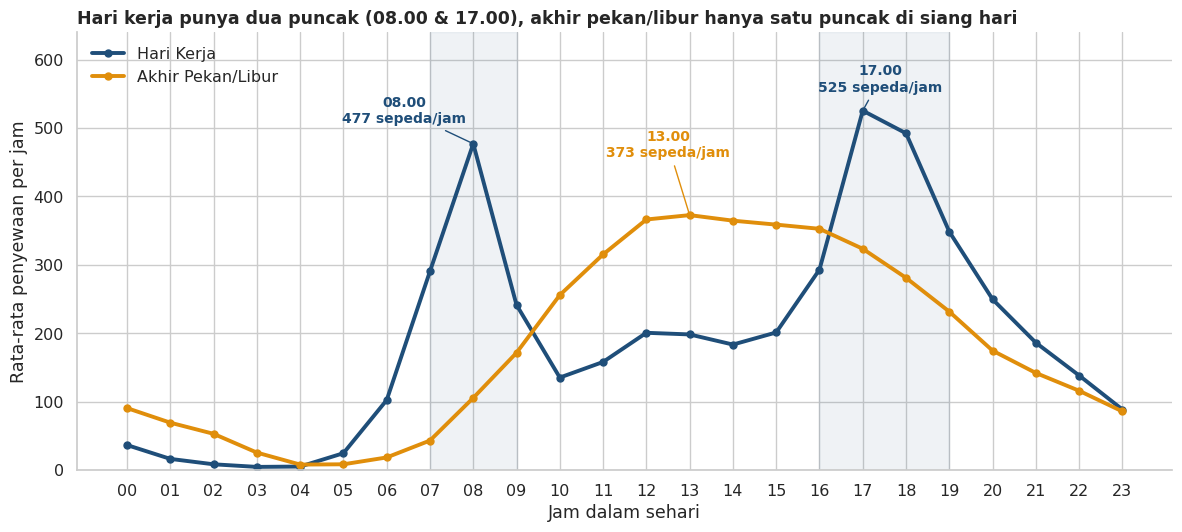

In [47]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axvspan(7, 9, color=BLUE, alpha=0.07)
ax.axvspan(16, 19, color=BLUE, alpha=0.07)
ax.plot(pola_jam.index, pola_jam['Hari Kerja'], color=BLUE, lw=2.8, marker='o', ms=5, label='Hari Kerja')
ax.plot(pola_jam.index, pola_jam['Akhir Pekan/Libur'], color=ORANGE, lw=2.8, marker='o', ms=5, label='Akhir Pekan/Libur')

for jam, nilai, warna, dx, dy in [(8, pola_jam.loc[8, 'Hari Kerja'], BLUE, -1.6, 30),
                                  (17, pola_jam.loc[17, 'Hari Kerja'], BLUE, 0.4, 28)]:
    ax.annotate(f'{jam:02d}.00\n{nilai:.0f} sepeda/jam', (jam, nilai), (jam + dx, nilai + dy),
                ha='center', color=warna, fontweight='bold', fontsize=10,
                arrowprops=dict(arrowstyle='-', color=warna))
jam_we = pola_jam['Akhir Pekan/Libur'].idxmax()
ax.annotate(f'{jam_we:02d}.00\n{pola_jam.loc[jam_we, "Akhir Pekan/Libur"]:.0f} sepeda/jam',
            (jam_we, pola_jam.loc[jam_we, 'Akhir Pekan/Libur']),
            (jam_we - 0.5, pola_jam.loc[jam_we, 'Akhir Pekan/Libur'] + 85),
            ha='center', color=ORANGE, fontweight='bold', fontsize=10,
            arrowprops=dict(arrowstyle='-', color=ORANGE))

ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{h:02d}' for h in range(24)])
ax.set_xlabel('Jam dalam sehari')
ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_ylim(0, 640)
ax.set_title('Hari kerja punya dua puncak (08.00 & 17.00), akhir pekan/libur hanya satu puncak di siang hari',
             loc='left', fontsize=12.5, fontweight='bold')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

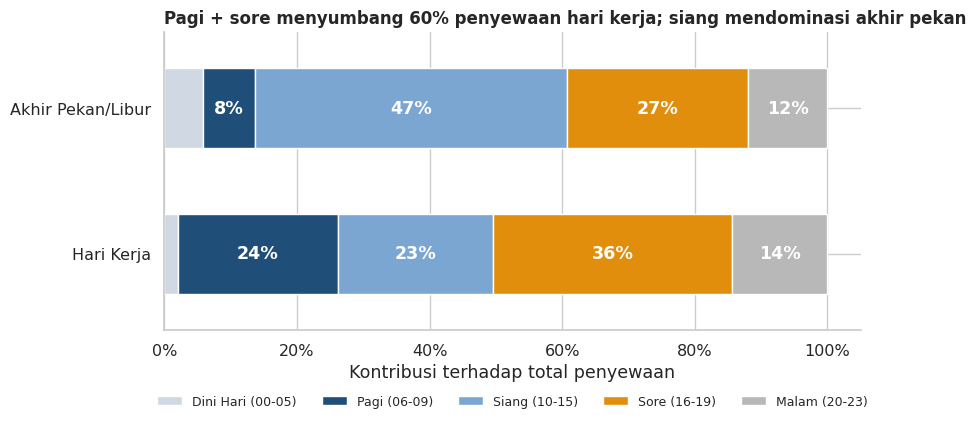

In [48]:
fig, ax = plt.subplots(figsize=(9, 4.5))
data_segmen = (kontribusi.div(kontribusi.sum(axis=1), axis=0) * 100).loc[['Hari Kerja', 'Akhir Pekan/Libur']]
data_segmen.plot(kind='barh', stacked=True, ax=ax, width=0.55,
                 color=['#cfd8e3', BLUE, '#7aa6d1', ORANGE, GREY])
for i, (idx, baris) in enumerate(data_segmen.iterrows()):
    kiri = 0
    for nilai in baris:
        if nilai > 6:
            ax.text(kiri + nilai / 2, i, f'{nilai:.0f}%', ha='center', va='center', color='white', fontweight='bold')
        kiri += nilai
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Kontribusi terhadap total penyewaan')
ax.set_ylabel('')
ax.set_title('Pagi + sore menyumbang 60% penyewaan hari kerja; siang mendominasi akhir pekan',
             loc='left', fontsize=12, fontweight='bold')
ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=9)
plt.tight_layout()
plt.show()

**Penjelasan Pertanyaan 1:** Pada **hari kerja** penyewaan memuncak dua kali, **08.00 (≈477)** dan **17.00 (≈525)**, konsisten dengan jam berangkat dan pulang kerja (dugaan; dataset tidak memuat tujuan perjalanan). Pada **akhir pekan/libur** puncaknya hanya **13.00 (≈373)**. Selisih puncak tertinggi: hari kerja 17.00 sekitar **41% lebih tinggi** dari puncak akhir pekan (525 vs 373). Segmen pagi (06–09) dan sore (16–19) menyumbang ±60% penyewaan hari kerja.

### Pertanyaan 2
*Berapa persen perbedaan rata-rata penyewaan harian pada kondisi cuaca berkabut/berawan dan hujan/salju ringan dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011–2012, agar tim pemasaran dapat menentukan waktu promosi dan kebijakan ukuran armada?*

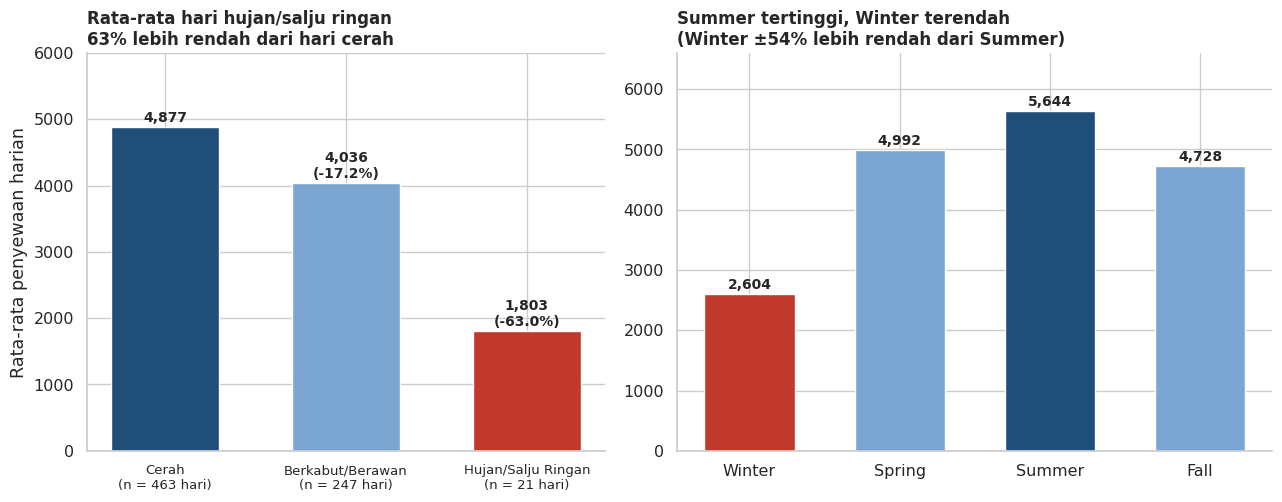

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})

# --- Panel kiri: cuaca ---
ax = axes[0]
warna_cuaca = [BLUE, '#7aa6d1', RED]
bars = ax.bar(cuaca.index, cuaca['rata_rata'], color=warna_cuaca, width=0.6)
for bar, (nama, baris) in zip(bars, cuaca.iterrows()):
    label = f"{baris['rata_rata']:,.0f}"
    if nama != 'Cerah':
        label += f"\n({baris['selisih_vs_cerah_%']:+.1f}%)"
    ax.text(bar.get_x() + bar.get_width() / 2, baris['rata_rata'] + 80, label, ha='center', fontweight='bold', fontsize=10)
ax.set_xticklabels([f"{n}\n(n = {int(j)} hari)" for n, j in zip(cuaca.index, cuaca['jumlah_hari'])], fontsize=9.5)
ax.set_ylim(0, 6000)
ax.set_ylabel('Rata-rata penyewaan harian')
ax.set_title('Rata-rata hari hujan/salju ringan\n63% lebih rendah dari hari cerah', loc='left', fontsize=12, fontweight='bold')

# --- Panel kanan: musim ---
ax = axes[1]
warna_musim = [RED, '#7aa6d1', BLUE, '#7aa6d1']
bars = ax.bar(musim.index, musim['rata_rata'], color=warna_musim, width=0.6)
for bar, nilai in zip(bars, musim['rata_rata']):
    ax.text(bar.get_x() + bar.get_width() / 2, nilai + 80, f'{nilai:,.0f}', ha='center', fontweight='bold', fontsize=10)
ax.set_ylim(0, 6600)
ax.set_ylabel('')
ax.set_title('Summer tertinggi, Winter terendah\n(Winter ±54% lebih rendah dari Summer)', loc='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Penjelasan Pertanyaan 2:** Dibanding hari cerah (±4.877/hari), rata-rata penyewaan harian **17,2% lebih rendah** saat berkabut/berawan dan **63,0% lebih rendah** saat hujan/salju ringan. Dari sisi musim, **Summer** tertinggi (±5.644/hari) dan **Winter** terendah (±2.604/hari), atau sekitar 54% lebih rendah. Hari hujan/salju ringan hanya 21 hari (2,9% hari) dan menyumbang 37.869 penyewaan atau **1,15%** dari total; selisih ilustratifnya terhadap rata-rata hari cerah sekitar 64.500 penyewaan (±2,0% dari total). Perbandingan ini bersifat deskriptif, bukan pembuktian sebab-akibat, dan kelompok hujan hanya 21 hari dibanding 463 hari cerah.

### Pertanyaan 3
*Berapa persentase pertumbuhan total penyewaan tahun 2012 dibandingkan 2011 (secara keseluruhan, per bulan, serta per segmen pengguna casual vs registered), agar manajemen dapat menentukan segmen yang harus diprioritaskan pada strategi akuisisi dan retensi?*

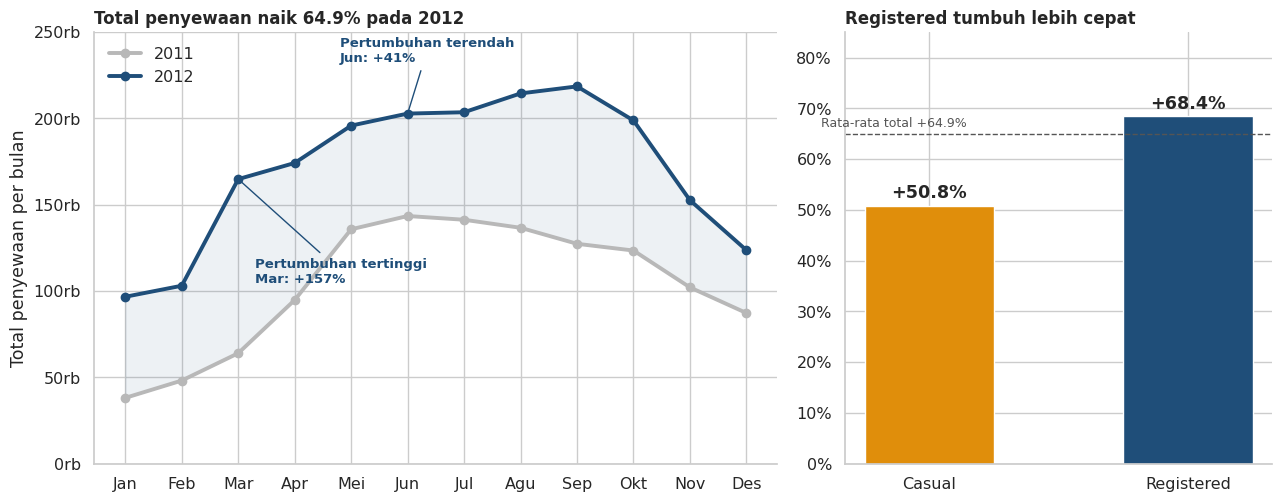

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.6, 1]})

# --- Panel kiri: tren bulanan ---
ax = axes[0]
bln = bulanan.reset_index()
ax.plot(bln['month_name'], bln[2011], color=GREY, lw=2.8, marker='o', label='2011')
ax.plot(bln['month_name'], bln[2012], color=BLUE, lw=2.8, marker='o', label='2012')
ax.fill_between(bln['month_name'], bln[2011], bln[2012], color=BLUE, alpha=0.08)
idx_maks = bln['pertumbuhan_%'].idxmax()
idx_min = bln['pertumbuhan_%'].idxmin()
ax.annotate(f"Pertumbuhan tertinggi\n{bln.loc[idx_maks, 'month_name']}: +{bln.loc[idx_maks, 'pertumbuhan_%']:.0f}%",
            (idx_maks, bln.loc[idx_maks, 2012]), (idx_maks + 0.3, bln.loc[idx_maks, 2012] - 60000),
            fontsize=9.5, color=BLUE, fontweight='bold', arrowprops=dict(arrowstyle='-', color=BLUE))
ax.annotate(f"Pertumbuhan terendah\n{bln.loc[idx_min, 'month_name']}: +{bln.loc[idx_min, 'pertumbuhan_%']:.0f}%",
            (idx_min, bln.loc[idx_min, 2012]), (idx_min - 1.2, bln.loc[idx_min, 2012] + 30000),
            fontsize=9.5, color=BLUE, fontweight='bold', arrowprops=dict(arrowstyle='-', color=BLUE))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f}rb'))
ax.set_ylim(0, 250000)
ax.set_ylabel('Total penyewaan per bulan')
ax.set_title(f"Total penyewaan naik {pertumbuhan_tahunan['total']:.1f}% pada 2012", loc='left', fontsize=12, fontweight='bold')
ax.legend(frameon=False, loc='upper left')

# --- Panel kanan: pertumbuhan per segmen ---
ax = axes[1]
seg = pertumbuhan_tahunan[['casual', 'registered']]
bars = ax.bar(['Casual', 'Registered'], seg.values, color=[ORANGE, BLUE], width=0.5)
for bar, nilai in zip(bars, seg.values):
    ax.text(bar.get_x() + bar.get_width() / 2, nilai + 1.5, f'+{nilai:.1f}%', ha='center', fontweight='bold')
ax.axhline(pertumbuhan_tahunan['total'], color='#555555', ls='--', lw=1)
ax.text(-0.42, pertumbuhan_tahunan['total'] + 1.5, f"Rata-rata total +{pertumbuhan_tahunan['total']:.1f}%", ha='left', fontsize=9, color='#555555')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 85)
ax.set_title('Registered tumbuh lebih cepat', loc='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Penjelasan Pertanyaan 3:** Penyewaan 2012 mencapai ±2,05 juta, tumbuh **64,9%** dari ±1,24 juta di 2011. Segmen **registered tumbuh +68,4%**, lebih tinggi daripada **casual +50,8%**. Pertumbuhan bulanan tertinggi terjadi di **Maret (+157%)** dan terendah di **Juni (+41%)**. Bulan dengan total tertinggi adalah Juni pada 2011 (±143,5 ribu) dan **September pada 2012 (±218,6 ribu; +71,5% dibanding September 2011)**.

**Insight:**
- Rata-rata penyewaan hari kerja memuncak pada 08.00 dan 17.00, sedangkan pada akhir pekan/libur memuncak di siang hari (13.00).
- Rata-rata penyewaan berbeda besar menurut cuaca dan musim: 17% lebih rendah saat berkabut dan 63% lebih rendah saat hujan ringan dibanding hari cerah, serta Winter 54% lebih rendah dari Summer (perbandingan deskriptif).
- Total penyewaan 2012 tumbuh 64,9% dibanding 2011, dengan pengguna registered tumbuh lebih cepat (+68,4%) daripada casual (+50,8%).

## Analisis Lanjutan (Opsional)

Analisis lanjutan memakai **manual grouping** dan **binning** (tanpa algoritma *machine learning*), relevan karena data berisi variabel numerik kontinu (suhu, jumlah penyewaan) yang lebih mudah ditindaklanjuti bila dikelompokkan:
1. **Binning suhu** (`pd.cut`) : Dingin (< 10°C), Sejuk (10–20°C), Hangat (20–28°C), Panas (≥ 28°C).
2. **Klasterisasi hari berdasarkan tingkat permintaan** (manual grouping dengan ambang bisnis): Rendah (< 3.000), Sedang (3.000–4.999), Tinggi (5.000–6.999), Sangat Tinggi (≥ 7.000 penyewaan/hari).

Pengelompokan suhu dan klaster permintaan dibuat di sel berikut, lalu dirangkum per kelompok.

In [51]:
# 1) Binning suhu
day_clean['kelompok_suhu'] = pd.cut(day_clean['temp_c'], bins=[-np.inf, 10, 20, 28, np.inf],
                                    labels=['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-28°C)', 'Panas (≥28°C)'],
                                    right=False)
suhu = day_clean.groupby('kelompok_suhu')['total'].agg(rata_rata='mean', median='median', jumlah_hari='count').round(0)

# 2) Klaster hari berdasarkan tingkat permintaan
day_clean['klaster_permintaan'] = pd.cut(day_clean['total'], bins=[0, 3000, 5000, 7000, np.inf],
                                         labels=['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'], right=False)
klaster_musim = (pd.crosstab(day_clean['season_name'], day_clean['klaster_permintaan'], normalize='index') * 100
                 ).reindex(urutan_musim).round(1)
print(suhu, '\n')
print(day_clean['klaster_permintaan'].value_counts().reindex(['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']), '\n')
klaster_musim

                  rata_rata  median  jumlah_hari
kelompok_suhu                                   
Dingin (<10°C)       1678.0  1530.0           60
Sejuk (10-20°C)      3692.0  3649.0          299
Hangat (20-28°C)     5581.0  5236.0          222
Panas (≥28°C)        5661.0  5523.0          150 

klaster_permintaan
Rendah           172
Sedang           273
Tinggi           192
Sangat Tinggi     94
Name: count, dtype: int64 



klaster_permintaan,Rendah,Sedang,Tinggi,Sangat Tinggi
season_name,,,,
Winter,64.6,29.8,5.0,0.6
Spring,13.6,39.1,34.8,12.5
Summer,2.1,39.9,34.0,23.9
Fall,14.6,40.4,30.9,14.0


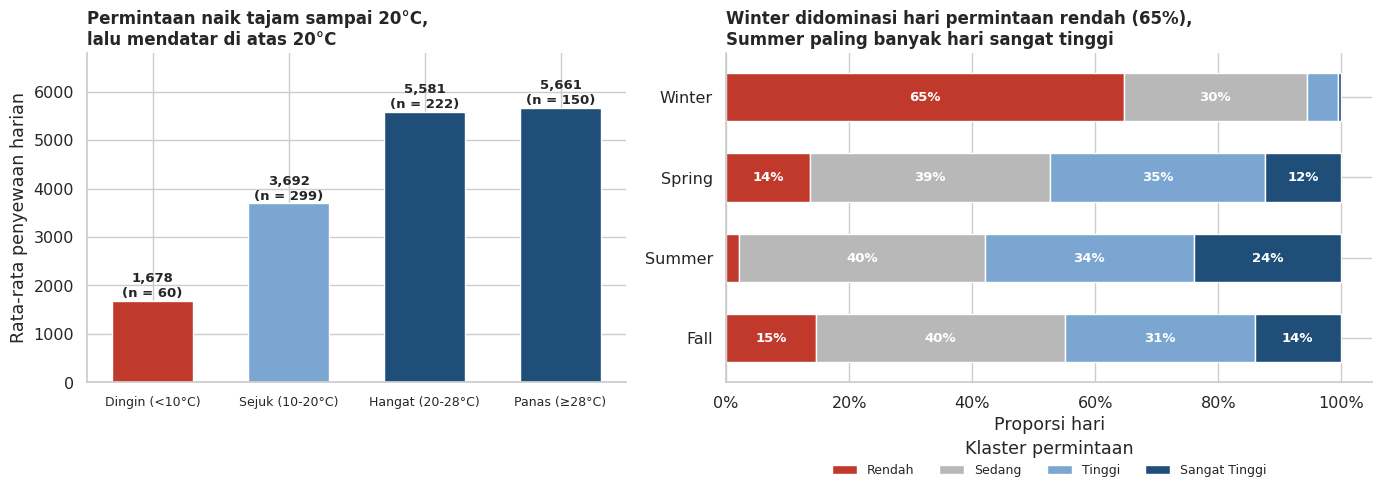

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.2]})

# --- Panel kiri: binning suhu ---
ax = axes[0]
warna = [RED, '#7aa6d1', BLUE, BLUE]
bars = ax.bar(suhu.index.astype(str), suhu['rata_rata'], color=warna, width=0.6)
for bar, (nama, baris) in zip(bars, suhu.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, baris['rata_rata'] + 80,
            f"{baris['rata_rata']:,.0f}\n(n = {int(baris['jumlah_hari'])})", ha='center', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 6800)
ax.set_ylabel('Rata-rata penyewaan harian')
ax.set_title('Permintaan naik tajam sampai 20°C,\nlalu mendatar di atas 20°C', loc='left', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', labelsize=9)

# --- Panel kanan: klaster permintaan per musim ---
ax = axes[1]
klaster_musim.plot(kind='barh', stacked=True, ax=ax, width=0.6, color=[RED, GREY, '#7aa6d1', BLUE])
for i, (idx, baris) in enumerate(klaster_musim.iterrows()):
    kiri = 0
    for nilai in baris:
        if nilai >= 8:
            ax.text(kiri + nilai / 2, i, f'{nilai:.0f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
        kiri += nilai
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Proporsi hari')
ax.set_ylabel('')
ax.set_title('Winter didominasi hari permintaan rendah (65%),\nSummer paling banyak hari sangat tinggi', loc='left', fontsize=12, fontweight='bold')
ax.legend(title='Klaster permintaan', frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.14), fontsize=9)
plt.tight_layout()
plt.show()

**Insight:**
- **Binning suhu:** rata-rata penyewaan melonjak dari ±1.678 (< 10°C) ke ±3.692 (10–20°C) dan ±5.581 (20–28°C), lalu relatif sama di ≥ 28°C (±5.661). Artinya kenaikan rata-rata penyewaan terlihat sampai kelompok suhu 20–28°C, dan rata-rata penyewaan pada kelompok Panas (±5.661) hampir sama dengan kelompok Hangat (±5.581).
- **Klaster permintaan:** 65% hari Winter masuk klaster *Rendah* dan hampir tidak ada hari *Sangat Tinggi*, sedangkan 24% hari Summer masuk klaster *Sangat Tinggi*. Hal ini membantu perencanaan kapasitas armada per musim.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** *Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak tersebut, agar tim operasional dapat menjadwalkan redistribusi dan perawatan sepeda di luar jam puncak?*

  Pada **hari kerja**, rata-rata penyewaan per jam memuncak dua kali: pukul **08.00 (±477)** dan **17.00 (±525, puncak tertinggi)**, sedangkan pada **akhir pekan/libur** puncaknya hanya satu, pukul **13.00 (±373)**. Puncak tertinggi hari kerja **±41% lebih tinggi** dari puncak akhir pekan (525 vs 373). Pukul 06.00–09.00 dan 16.00–19.00 menyumbang ±60% penyewaan hari kerja, sedangkan pukul 10.00–15.00 menyumbang 47% penyewaan akhir pekan; pukul 00.00–05.00 hanya 2,1% (hari kerja) dan 5,9% (akhir pekan). Catatan: uji pada hari lengkap 24 jam menunjukkan jam puncak sama, dengan nilai puncak 4,9–6,5% lebih tinggi.
- **Conclusion pertanyaan 2:** *Berapa persen perbedaan rata-rata penyewaan harian pada kondisi cuaca berkabut/berawan dan hujan/salju ringan dibandingkan cuaca cerah, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011–2012, agar tim pemasaran dapat menentukan waktu promosi dan kebijakan ukuran armada?*

  Dibanding hari cerah (±4.877/hari), rata-rata penyewaan harian **17,2% lebih rendah** pada cuaca berkabut/berawan (±4.036) dan **63,0% lebih rendah** pada hujan/salju ringan (±1.803). **Summer** memiliki rata-rata tertinggi (±5.644/hari) dan **Winter** terendah (±2.604/hari, ±54% di bawah Summer). Hari hujan/salju ringan hanya 21 hari (2,9%) dan menyumbang 1,15% dari total penyewaan. Perbandingan ini deskriptif dan tidak membuktikan sebab-akibat.
- **Conclusion pertanyaan 3:** *Berapa persentase pertumbuhan total penyewaan tahun 2012 dibandingkan 2011 (secara keseluruhan, per bulan, serta per segmen pengguna casual vs registered), agar manajemen dapat menentukan segmen yang harus diprioritaskan pada strategi akuisisi dan retensi?*

  Total penyewaan 2012 tumbuh **64,9%** dibanding 2011 (1.243.103 menjadi 2.049.576). Pengguna **registered tumbuh +68,4%** dan **casual +50,8%**, sehingga porsi casual turun dari 19,9% menjadi 18,2%. Per bulan, pertumbuhan berkisar +41% (Juni) sampai +157% (Maret); bulan tertinggi 2012 adalah September (218.573), sedangkan pada 2011 adalah Juni (143.512).
- **Conclusion analisis lanjutan:** rata-rata penyewaan harian naik dari ±1.678 (< 10°C) ke ±3.692 (10–20°C) dan ±5.581 (20–28°C), lalu relatif sama pada ≥ 28°C (±5.661). Sebanyak 65% hari Winter masuk klaster permintaan *Rendah*, sedangkan 24% hari Summer masuk klaster *Sangat Tinggi*.

**Rekomendasi Action Item** (seluruhnya berbasis dimensi yang ada di data: waktu, cuaca, musim, suhu, dan jenis pengguna; dataset tidak memuat lokasi/stasiun sehingga tidak ada rekomendasi per area):
- **Jadwal ketersediaan dan redistribusi (Pertanyaan 1):** pastikan sepeda tersedia dan petugas redistribusi siap sebelum 07.00 dan sebelum 16.00 pada hari kerja (puncak 08.00 dan 17.00), serta sebelum siang pada akhir pekan/libur (puncak 13.00). Jadwalkan perawatan armada pada pukul 00.00–05.00, saat permintaan paling rendah (2,1% penyewaan hari kerja).
- **Promosi dan armada menurut musim dan cuaca (Pertanyaan 2):** uji coba promo (misalnya diskon atau paket langganan) pada musim Winter (±2.604/hari vs ±5.644/hari di Summer) dan pada hari berkabut/hujan ringan, lalu ukur apakah selisihnya menyempit. Pertahankan ketersediaan armada penuh pada Summer.
- **Prioritas segmen pengguna (Pertanyaan 3):** pertahankan pengguna registered yang tumbuh lebih cepat (+68,4%), dan tawarkan paket langganan kepada pengguna casual yang jauh lebih aktif pada akhir pekan/libur (±1.371/hari vs ±607/hari pada hari kerja).
- **Perencanaan permintaan harian:** gunakan prakiraan suhu dan cuaca sebagai masukan; di bawah 10°C rata-rata penyewaan ±70% lebih rendah dari kelompok hangat (±1.678 vs ±5.581).
- **Keterbatasan:** data 2011–2012 dari satu sistem dan tidak memuat lokasi; ada 165 jam tidak tercatat; hubungan antarvariabel bersifat deskriptif, sehingga target operasional perlu divalidasi dengan data terbaru.